In [1]:
# Environment setup — run this cell first
# Standard library only; no extra installs required for the notebook itself.
# Django examples require: pip install django
# For diagram rendering: pip install Pillow matplotlib

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

def render_diagram(image_path, size=(12, 7), caption=None, dpi=120):
    """
    Render a technical diagram in the notebook.

    Parameters
    ----------
    image_path : str or pathlib.Path
        Path to the diagram image, relative to this notebook.
    size : tuple[float, float]
        Figure width and height in inches.
    caption : str, optional
        Descriptive caption displayed below the diagram.
    dpi : int
        Rendering resolution.
    """
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Diagram not found: {image_path}")

    with Image.open(image_path) as source:
        image = source.convert("RGBA")

    fig, ax = plt.subplots(figsize=size, dpi=dpi)
    ax.imshow(image)
    ax.axis("off")

    if caption:
        fig.text(0.5, 0.02, caption, ha="center", va="bottom", wrap=True, fontsize=10)
        fig.subplots_adjust(bottom=0.12)
    else:
        fig.tight_layout(pad=0)

    plt.show()

print("Setup complete. render_diagram() is ready.")


Setup complete. render_diagram() is ready.


# Django 4 Forms and ModelForms — Complete Learning Guide

This notebook is a self-contained learning resource covering Django's form and ModelForm system from first principles through advanced validation and user-experience enhancements.

---

## Prerequisites

- Python 3.10+
- Basic Django familiarity (models, views, URL routing, templates)
- Django 4.2 installed (`pip install django`)

---

## Learning Objectives

By the end of this course you will be able to:

1. Explain the difference between raw HTML forms and Django's Form classes.
2. Describe the Django form lifecycle — from first GET request through validation to redirect.
3. Build and render `Form` and `ModelForm` classes.
4. Apply built-in and custom validators to form fields and model fields.
5. Understand and implement CSRF protection in Django forms.
6. Override validation lifecycle methods (`clean_<field>`, `clean`, `to_python`, etc.).
7. Customise form appearance using widget attributes and CSS.
8. Trace validation errors through Django's error-handling system.

---

## Table of Contents

1. [Django Project Structure](#1-django-project-structure)
2. [What Is a Django Form?](#2-what-is-a-django-form)
3. [The Django Form Lifecycle](#3-the-django-form-lifecycle)
4. [Form Field Validation Chain](#4-form-field-validation-chain)
5. [Building a Basic Form](#5-building-a-basic-form)
6. [Building a ModelForm](#6-building-a-modelform)
7. [The ModelForm Validation Chain](#7-the-modelform-validation-chain)
8. [Built-in Validators](#8-built-in-validators)
9. [CSRF Security](#9-csrf-security)
10. [Custom Validation Methods](#10-custom-validation-methods)
11. [Form Lifecycle Method Overrides](#11-form-lifecycle-method-overrides)
12. [Customising Form Appearance](#12-customising-form-appearance)
13. [Handling and Displaying Validation Errors](#13-handling-and-displaying-validation-errors)
14. [Enhancing User Experience with CSS and Widgets](#14-enhancing-user-experience-with-css-and-widgets)
15. [Reference Tables](#15-reference-tables)
16. [Exercises and Knowledge Checks](#16-exercises-and-knowledge-checks)
17. [Final Assessment](#17-final-assessment)

---

*Source coverage: 4 PDF modules, 52 slides total.*  
*See `source_coverage.md` for a complete page-level mapping.*


---
## 1. Django Project Structure

*Source coverage: creating-and-handling-forms-slides.pdf, pages 2–6*

Before working with forms it is helpful to understand the standard file layout Django generates when you create a project and an application. Forms are typically defined inside the application, and templates are referenced through the URL configuration.

### 1.1 Version note

This material was written for **Django 4.2** and **Python 3.10**. The form and validation APIs covered here are stable across the 4.x series.

### 1.2 Standard directory layout

A minimal Django project has the following structure:

```
DjangoProject/
├── core/                   ← Project package (named when you run startproject)
│   ├── asgi.py
│   ├── settings.py
│   └── urls.py
│   └── wsgi.py
└── application/            ← Django application (created with startapp)
    ├── migrations/
    ├── admin.py
    ├── apps.py
    ├── models.py
    ├── views.py
    └── tests.py
```

Forms are added by creating a `forms.py` file inside the application directory.  
Templates can live in `application/templates/` or a project-level `templates/` directory configured in `settings.py`.

| File | Role |
|------|------|
| `core/settings.py` | Project-wide configuration (databases, installed apps, templates) |
| `core/urls.py` | Root URL configuration — includes per-app URL patterns |
| `application/models.py` | ORM model definitions |
| `application/forms.py` | Form and ModelForm definitions *(you create this file)* |
| `application/views.py` | View functions or class-based views |
| `application/templates/` | HTML templates rendered by views |


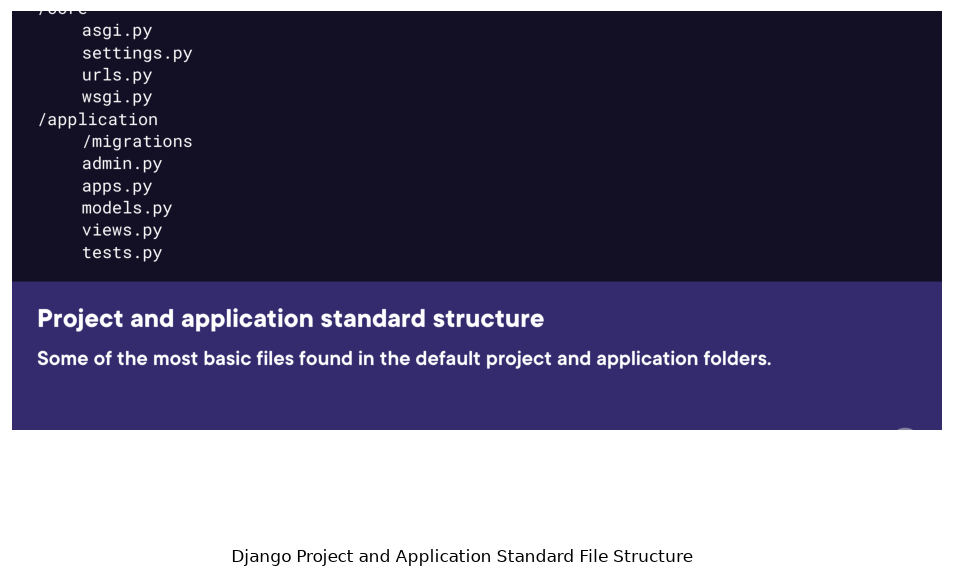

In [2]:
render_diagram(
    "assets/diagrams/project_structure_layout.png",
    size=(10, 6),
    caption="Django Project and Application Standard File Structure"
)


---
## 2. What Is a Django Form?

*Source coverage: creating-and-handling-forms-slides.pdf, pages 4, 12–15*

### 2.1 The problem with raw HTML forms

An HTML `<form>` lets the browser collect user input and submit it to the server.  
However, raw HTML forms have significant limitations:

- **No automatic validation** — you must write server-side checks manually.
- **No CSRF protection** — you must add and verify tokens yourself.
- **No Python representation** — the form data arrives as a raw `QueryDict` in `request.POST`.
- **Repetitive rendering** — you write widget markup by hand for every field.

### 2.2 Django Form classes

Django solves all of the above by providing two complementary form abstractions:

| Class | Purpose |
|-------|---------|
| `django.forms.Form` | A general-purpose form with manually declared fields |
| `django.forms.ModelForm` | A form automatically generated from a model class |

Both give you:
- **Automatic HTML rendering** (as `<p>`, `<ul>`, `<table>`, or individual widgets)
- **Data cleaning and validation** through a well-defined lifecycle
- **CSRF token injection** via the `{% csrf_token %}` template tag
- **A `cleaned_data` dictionary** of validated, Python-typed values

### 2.3 Bound vs unbound forms

A Django form is either *bound* (attached to submitted data) or *unbound* (empty).

| State | When | Behaviour |
|-------|------|-----------|
| Unbound | First page load (GET request) | Renders empty widgets; `is_valid()` always returns `False` |
| Bound | POST request with user data | Can be validated with `is_valid()`; populates `cleaned_data` on success |

```python
# Unbound — create with no arguments
form = ContactForm()

# Bound — pass POST data
form = ContactForm(data=request.POST)
```


---
## 3. The Django Form Lifecycle

*Source coverage: creating-and-handling-forms-slides.pdf, pages 7–8*

Every form request follows the same high-level lifecycle:

1. **First request (GET):** The view creates an *unbound* form and renders it.
2. **Submission (POST):** The view creates a *bound* form with `request.POST`.
3. **Validation:** `form.is_valid()` runs the full validation chain.
4. **Success path:** Process the action, then redirect (Post/Redirect/Get pattern).
5. **Failure path:** Re-render the form with errors so the user can correct input.

The flowchart below illustrates the decision logic:


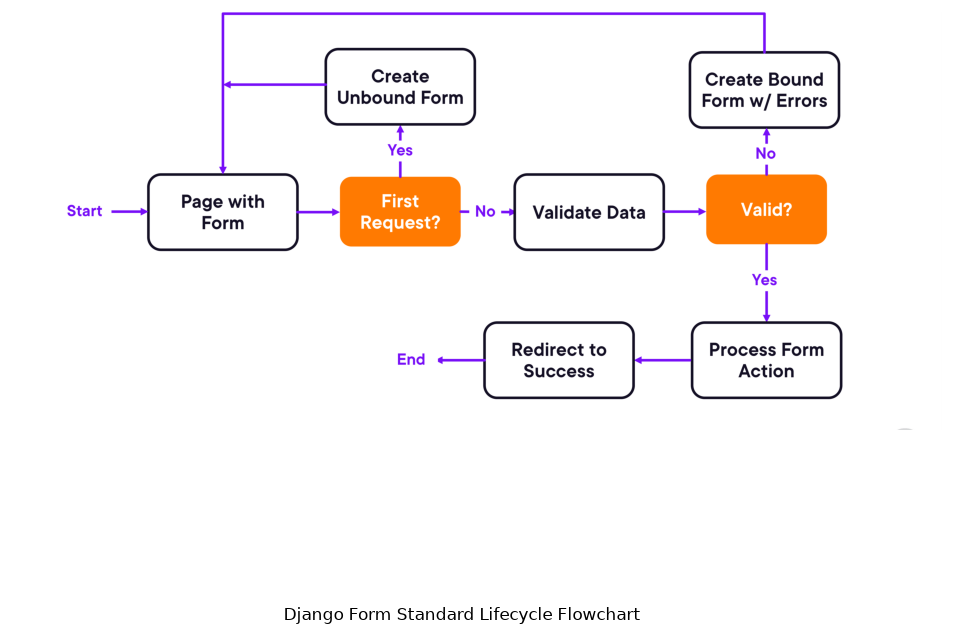

In [3]:
render_diagram(
    "assets/diagrams/form_lifecycle_full.png",
    size=(10, 7),
    caption="Django Form Standard Lifecycle Flowchart"
)


### 3.1 View skeleton

The standard view pattern that implements this lifecycle is:

```python
# application/views.py
from django.shortcuts import render, redirect
from .forms import ContactForm

def contact_view(request):
    if request.method == 'POST':
        form = ContactForm(data=request.POST)
        if form.is_valid():
            # Access validated data
            name = form.cleaned_data['name']
            email = form.cleaned_data['email']
            # ... process the data ...
            return redirect('success')          # Post/Redirect/Get
    else:
        form = ContactForm()                    # Unbound for GET

    return render(request, 'contact.html', {'form': form})
```

The `else` branch handles the GET request (initial page load) and any POST that fails validation — the same template is rendered in both cases but the form object carries errors on the failure re-render.

### 3.2 Template skeleton

```html
<!-- templates/contact.html -->
<form method="post">
    {% csrf_token %}
    {{ form.as_p }}
    <button type="submit">Submit</button>
</form>
```

The `{% csrf_token %}` tag is **required**. Omitting it causes a `403 Forbidden` on POST (see [Chapter 9](#9-csrf-security)).

### 3.3 URL configuration

```python
# core/urls.py  (or application/urls.py included from core)
from django.urls import path
from application.views import contact_view

urlpatterns = [
    path('contact/', contact_view, name='contact'),
]
```


---
## 4. Form Field Validation Chain

*Source coverage: creating-and-handling-forms-slides.pdf, pages 9 (Form); pages 10–11 (ModelForm)*

When `form.is_valid()` is called, Django runs each field through a fixed sequence of steps. Understanding this sequence is essential for knowing *where* to place custom validation logic.

### 4.1 Per-field sequence for `Form`

| Step | Method | Who can override | Purpose |
|------|--------|-----------------|---------|
| 1 | `to_python()` | Custom field subclass | Convert raw string → Python type |
| 2 | `validate()` | Custom field subclass | Field-level required/empty check |
| 3 | `run_validators()` | Automatic | Run each validator in `validators=[]` |
| 4 | `clean()` (field) | Custom field subclass | Combines steps 1–3, returns cleaned value |
| 5 | `clean_<fieldname>()` | **Form class** | Field-specific cross-field or business logic |
| 6 | `clean()` (form) | **Form class** | Cross-field validation using `cleaned_data` |


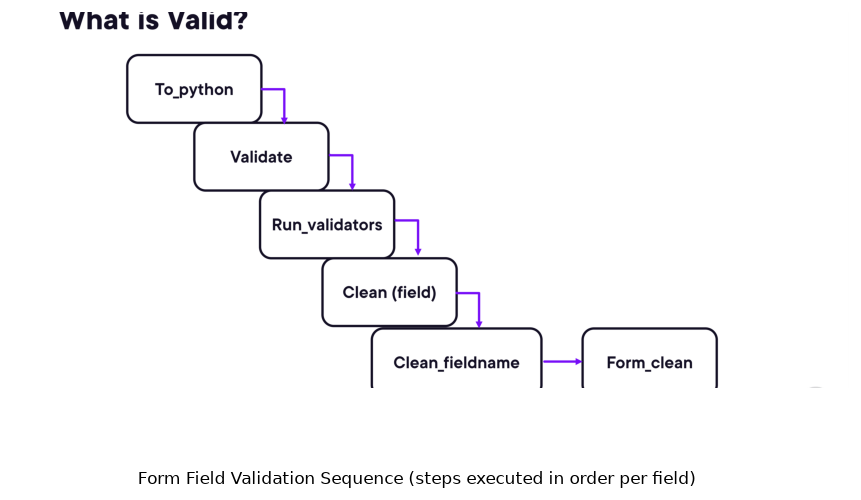

In [4]:
render_diagram(
    "assets/diagrams/form_validation_steps.png",
    size=(9, 5),
    caption="Form Field Validation Sequence (steps executed in order per field)"
)


### 4.2 Key points

- If `to_python()` or `validate()` raises `ValidationError`, subsequent steps for that field are skipped.
- `clean_<fieldname>()` is called **only if** the field-level steps succeeded.
- `clean()` on the form is called after **all** fields have been processed.
- Errors from any step are collected in `form.errors` (a dict keyed by field name, or `__all__` for non-field errors).
- `form.cleaned_data` is only populated for fields that passed all their steps.


---
## 5. Building a Basic Form

*Source coverage: creating-and-handling-forms-slides.pdf, pages 12–13*

A `forms.Form` subclass declares each input as a class attribute using Django field types.

### 5.1 Defining the form

```python
# application/forms.py
from django import forms

class CommentForm(forms.Form):
    name = forms.CharField(
        required=True,
        label="Your name",
        max_length=100,
        widget=forms.TextInput(attrs={'placeholder': 'Enter your name'}),
    )
    email = forms.EmailField(
        required=True,
        label="Email address",
    )
    message = forms.CharField(
        required=True,
        label="Message",
        widget=forms.Textarea(attrs={'rows': 5}),
    )
```

### 5.2 Common field types

| Field class | HTML input rendered | Python type returned |
|-------------|---------------------|---------------------|
| `CharField` | `<input type="text">` | `str` |
| `EmailField` | `<input type="email">` | `str` (validated email format) |
| `IntegerField` | `<input type="number">` | `int` |
| `BooleanField` | `<input type="checkbox">` | `bool` |
| `DateField` | `<input type="text">` | `datetime.date` |
| `ChoiceField` | `<select>` | `str` |
| `FileField` | `<input type="file">` | `UploadedFile` |
| `Textarea` | `<textarea>` | `str` |

### 5.3 Common field arguments

| Argument | Default | Effect |
|----------|---------|--------|
| `required` | `True` | Makes the field mandatory |
| `label` | derived from field name | Label text in the rendered form |
| `initial` | `None` | Default value shown in unbound form |
| `help_text` | `''` | Hint displayed next to the field |
| `widget` | field-type default | HTML widget class |
| `validators` | `[]` | Additional validator callables |
| `error_messages` | field defaults | Override error message strings |

### 5.4 Rendering options

```python
# In a template, given context {'form': form}

{{ form.as_p }}        # Wraps each field in <p> tags
{{ form.as_ul }}       # Wraps each field in <li> tags
{{ form.as_table }}    # Wraps each field in <tr> tags

# Manual rendering for full control:
{% for field in form %}
    <div class="field-group">
        {{ field.label_tag }}
        {{ field }}
        {% if field.errors %}
            <ul class="errors">
                {% for error in field.errors %}
                    <li>{{ error }}</li>
                {% endfor %}
            </ul>
        {% endif %}
    </div>
{% endfor %}
```


In [5]:
# Demonstration: introspect a Form without a running Django server
# (Django requires setup before importing its modules)

DEMO_FORM_CODE = '''
from django import forms

class CommentForm(forms.Form):
    name = forms.CharField(
        required=True,
        label="Your name",
        max_length=100,
    )
    email = forms.EmailField(required=True, label="Email address")
    message = forms.CharField(
        required=True,
        label="Message",
        widget=forms.Textarea(attrs={"rows": 5}),
    )
'''

print("CommentForm field definitions (conceptual):")
fields = [
    ("name",    "CharField",   "required=True, max_length=100"),
    ("email",   "EmailField",  "required=True"),
    ("message", "CharField",   "required=True, widget=Textarea"),
]
print(f"{'Field':<12} {'Type':<14} {'Key options'}")
print("-" * 50)
for name, ftype, opts in fields:
    print(f"{name:<12} {ftype:<14} {opts}")


CommentForm field definitions (conceptual):
Field        Type           Key options
--------------------------------------------------
name         CharField      required=True, max_length=100
email        EmailField     required=True
message      CharField      required=True, widget=Textarea


---
## 6. Building a ModelForm

*Source coverage: creating-and-handling-forms-slides.pdf, pages 14–15*

A `ModelForm` automatically generates form fields from a Django model. This eliminates the duplication of defining the same attributes in both the model and a separate form class.

### 6.1 When to use ModelForm vs Form

| Use `Form` when… | Use `ModelForm` when… |
|------------------|-----------------------|
| The form does not map to a model | The form creates or edits a model instance |
| You need full control over every field | You want to auto-generate fields from the model |
| You are building a search/filter form | You need `form.save()` to persist data |

### 6.2 Defining a model

```python
# application/models.py
from django.db import models

class Comment(models.Model):
    name    = models.CharField(max_length=100)
    email   = models.EmailField()
    message = models.TextField()
    created = models.DateTimeField(auto_now_add=True)

    def __str__(self):
        return f"Comment by {self.name}"
```

After defining a new model, run:
```bash
python manage.py makemigrations
python manage.py migrate
```

### 6.3 Defining the ModelForm

```python
# application/forms.py
from django import forms
from .models import Comment

class CommentModelForm(forms.ModelForm):
    class Meta:
        model  = Comment
        fields = ['name', 'email', 'message']   # or fields = '__all__'
        # exclude = ['created']                 # alternative: list fields to skip
        labels = {
            'name':    'Your name',
            'email':   'Email address',
            'message': 'Your message',
        }
        widgets = {
            'message': forms.Textarea(attrs={'rows': 5}),
        }
```

### 6.4 Using ModelForm in a view

```python
# application/views.py
from django.shortcuts import render, redirect
from .forms import CommentModelForm

def add_comment(request):
    if request.method == 'POST':
        form = CommentModelForm(data=request.POST)
        if form.is_valid():
            form.save()                   # Creates and saves the Comment instance
            return redirect('comment-list')
    else:
        form = CommentModelForm()
    return render(request, 'add_comment.html', {'form': form})
```

`form.save()` calls `model_instance.save()` internally. You can also pass `commit=False` to modify the instance before saving:

```python
if form.is_valid():
    comment = form.save(commit=False)
    comment.ip_address = request.META.get('REMOTE_ADDR')
    comment.save()
    return redirect('comment-list')
```

### 6.5 ModelForm field mapping

Django maps model field types to form field types automatically:

| Model field | Default form field |
|-------------|-------------------|
| `CharField` | `forms.CharField` |
| `TextField` | `forms.CharField(widget=Textarea)` |
| `EmailField` | `forms.EmailField` |
| `IntegerField` | `forms.IntegerField` |
| `BooleanField` | `forms.BooleanField` |
| `DateField` | `forms.DateField` |
| `ForeignKey` | `forms.ModelChoiceField` |
| `ManyToManyField` | `forms.ModelMultipleChoiceField` |


---
## 7. The ModelForm Validation Chain

*Source coverage: creating-and-handling-forms-slides.pdf, pages 10–11; managing-form-validation-errors-slides.pdf, pages 5–6*

`ModelForm` extends the standard `Form` validation chain with additional steps that enforce model-level constraints.


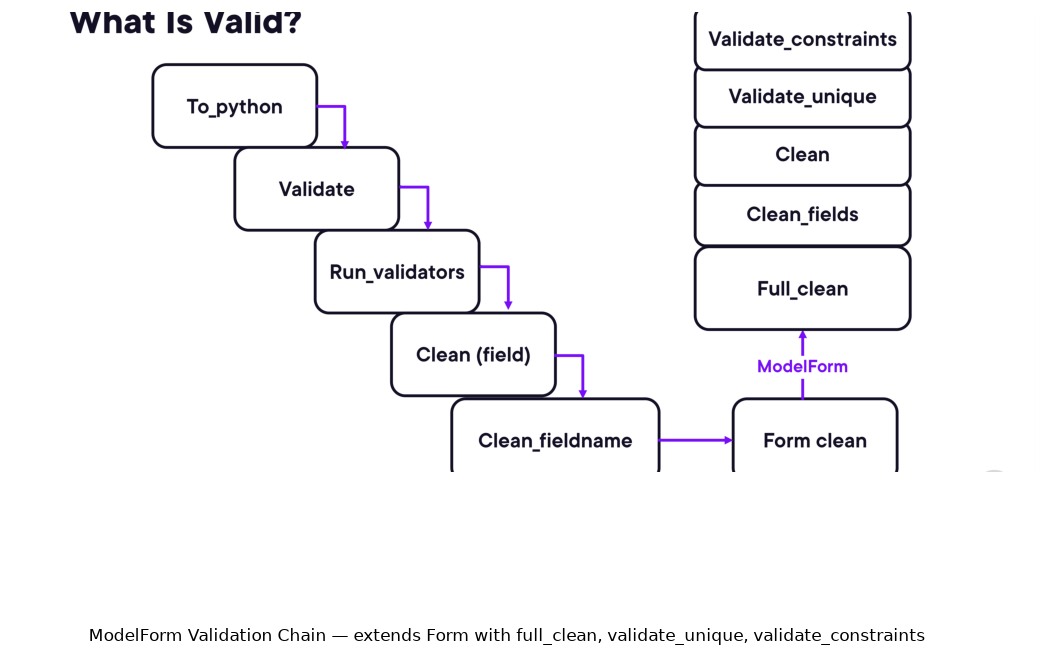

In [6]:
render_diagram(
    "assets/diagrams/modelform_validation_full.png",
    size=(11, 7),
    caption="ModelForm Validation Chain — extends Form with full_clean, validate_unique, validate_constraints"
)


### 7.1 Additional validation steps in ModelForm

| Step | Method | Purpose |
|------|--------|---------|
| 7 | `full_clean()` | Entry point — calls the three sub-steps below |
| 8 | `clean_fields()` | Validates each model field using field-level validation |
| 9 | `clean()` (model) | Cross-field model-level validation |
| 10 | `validate_unique()` | Enforces `unique=True` and `unique_together` constraints |
| 11 | `validate_constraints()` | Enforces `Meta.constraints` (Django 3.2+) |

The form-level steps (1–6 from Chapter 4) run first, then these model-level steps.

### 7.2 Comparison summary

| Method | Defined on | Override in |
|--------|-----------|-------------|
| `to_python()` | Field class | Custom field subclass |
| `validate()` | Field class | Custom field subclass |
| `run_validators()` | Field class | Automatic (via `validators=[]`) |
| `clean()` (field) | Field class | Custom field subclass |
| `clean_<fieldname>()` | Form / ModelForm | Your Form/ModelForm subclass |
| `clean()` (form) | Form / ModelForm | Your Form/ModelForm subclass |
| `full_clean()` | Model | Rarely — prefer model's `clean()` |
| `clean_fields()` | Model | Rarely |
| `clean()` (model) | Model | Your Model subclass |
| `validate_unique()` | Model | Rarely |
| `validate_constraints()` | Model | Rarely |


---
## 8. Built-in Validators

*Source coverage: ensuring-data-integrity-and-security-slides.pdf, pages 3–7*

Django provides a collection of reusable validators in `django.core.validators`. Validators are callables that accept a value and raise `ValidationError` if it fails.

### 8.1 Using validators

Validators can be applied to form fields:

```python
from django import forms
from django.core.validators import RegexValidator, MinLengthValidator

alpha_validator = RegexValidator(
    regex=r'^[a-zA-Z]*$',
    message='Name must contain alphabetic characters only.',
    code='invalid_name',
)

class CommentForm(forms.Form):
    name = forms.CharField(
        required=True,
        label="Your name",
        max_length=100,
        validators=[alpha_validator],
    )
```

They can also be applied to model fields:

```python
# application/models.py
from django.db import models
from django.core.validators import RegexValidator

alpha_validator = RegexValidator(
    regex=r'^[a-zA-Z]*$',
    message='Name must contain alphabetic characters only.',
    code='invalid_name',
)

class Comment(models.Model):
    name = models.CharField(
        null=True,
        blank=True,
        max_length=100,
        validators=[alpha_validator],
    )
```

When a validator is on the model field, it is automatically applied by `ModelForm` during validation.

### 8.2 Common built-in validators

| Validator | Import | Purpose |
|-----------|--------|---------|
| `RegexValidator` | `django.core.validators` | Validates value against a regular expression |
| `EmailValidator` | `django.core.validators` | Validates email address format |
| `URLValidator` | `django.core.validators` | Validates URL format |
| `MaxValueValidator` | `django.core.validators` | Numeric upper bound |
| `MinValueValidator` | `django.core.validators` | Numeric lower bound |
| `MaxLengthValidator` | `django.core.validators` | String length upper bound |
| `MinLengthValidator` | `django.core.validators` | String length lower bound |
| `FileExtensionValidator` | `django.core.validators` | Allowed file extensions |
| `validate_email` | `django.core.validators` | Standalone email validator callable |
| `validate_integer` | `django.core.validators` | Validates integer string |

### 8.3 RegexValidator in depth

`RegexValidator` is the most flexible built-in validator:

```python
from django.core.validators import RegexValidator

# Alpha only
alpha_only = RegexValidator(
    regex=r'^[a-zA-Z]*$',
    message='Only letters are allowed.',
    code='invalid_name',
)

# Alpha with spaces (note: \s matches any whitespace including tabs/newlines)
# For names, prefer an explicit space character:
alpha_with_spaces = RegexValidator(
    regex=r'^[a-zA-Z\s]*$',
    message='Only letters and spaces are allowed.',
    code='invalid_name',
)

# Phone number (basic)
phone_validator = RegexValidator(
    regex=r'^\+?[0-9]{7,15}$',
    message='Enter a valid phone number.',
    code='invalid_phone',
)
```

> **Note on `\s` vs a literal space:** `\s` matches any whitespace character, including tabs and newlines. If you specifically want to allow only letters and spaces, use `r'^[a-zA-Z ]*$'` (with an explicit space in the character class).

*Source coverage: enhancing-user-experience-slides.pdf, page 10 (regex with spaces)*


In [7]:
# Demonstrate RegexValidator behaviour without Django
import re

def check_regex_validator(value, pattern, message):
    if not re.match(pattern, value):
        raise ValueError(f"ValidationError: {message} (value={value!r})")
    return value

test_cases = [
    ("Alice",       r'^[a-zA-Z]*$',   "alpha only"),
    ("Alice Smith", r'^[a-zA-Z]*$',   "alpha only"),
    ("Alice Smith", r'^[a-zA-Z ]*$',  "alpha + space"),
    ("alice@x.com", r'^[\w.@+\-]+$', "email chars"),
    ("",            r'^.+$',           "non-empty"),
]

print(f"{'Value':<15} {'Pattern':<22} {'Result'}")
print("-" * 60)
for value, pattern, label in test_cases:
    try:
        check_regex_validator(value, pattern, "invalid input")
        result = "✓ valid"
    except ValueError as e:
        result = "✗ invalid"
    print(f"{value!r:<15} {label:<22} {result}")


Value           Pattern                Result
------------------------------------------------------------
'Alice'         alpha only             ✓ valid
'Alice Smith'   alpha only             ✗ invalid
'Alice Smith'   alpha + space          ✓ valid
'alice@x.com'   email chars            ✓ valid
''              non-empty              ✗ invalid


---
## 9. CSRF Security

*Source coverage: ensuring-data-integrity-and-security-slides.pdf, pages 8–12*

### 9.1 What is a CSRF attack?

**Cross-Site Request Forgery (CSRF)** exploits the trust a server has in a user's browser. An attacker tricks an already-authenticated user into unknowingly submitting a request to the target server.

The attack flow:

1. A legitimate user logs in to a banking site (a session cookie is set).
2. The user visits a malicious page controlled by the attacker.
3. The malicious page contains a hidden form that silently POSTs to the banking site.
4. Because the browser automatically sends the session cookie, the banking server processes the request as if it came from the legitimate user.


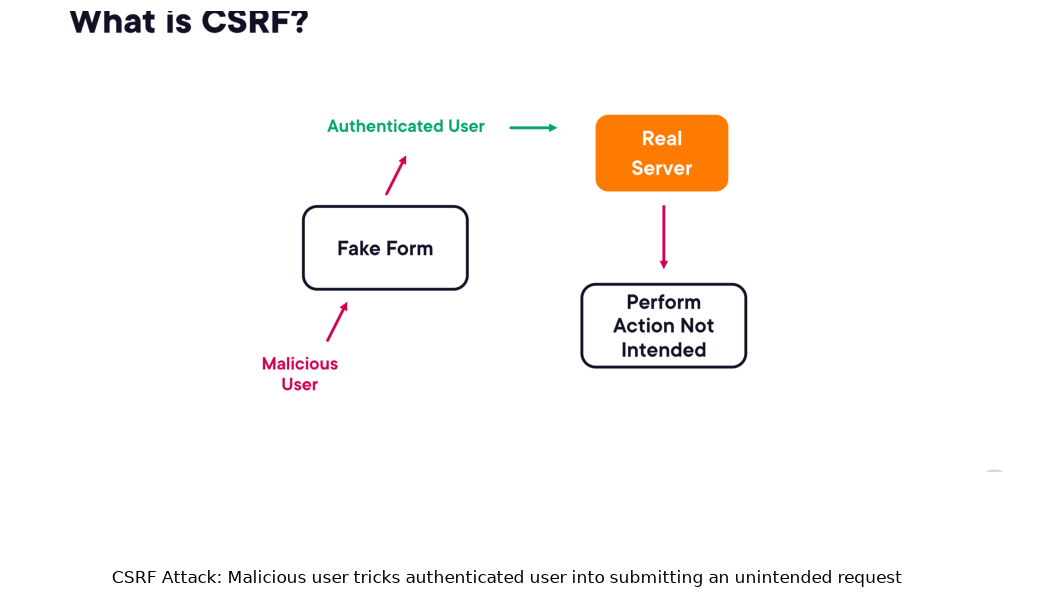

In [8]:
render_diagram(
    "assets/diagrams/csrf_attack_flow.png",
    size=(11, 6),
    caption="CSRF Attack: Malicious user tricks authenticated user into submitting an unintended request"
)


### 9.2 Django's CSRF protection

Django defends against CSRF by requiring a **secret token** in every POST request. The token is:
- Generated per-session (stored in a cookie).
- Embedded in every form rendered by Django via `{% csrf_token %}`.
- Validated by Django middleware on every unsafe HTTP method (POST, PUT, PATCH, DELETE).

If the token is missing or wrong, Django returns **403 Forbidden**.


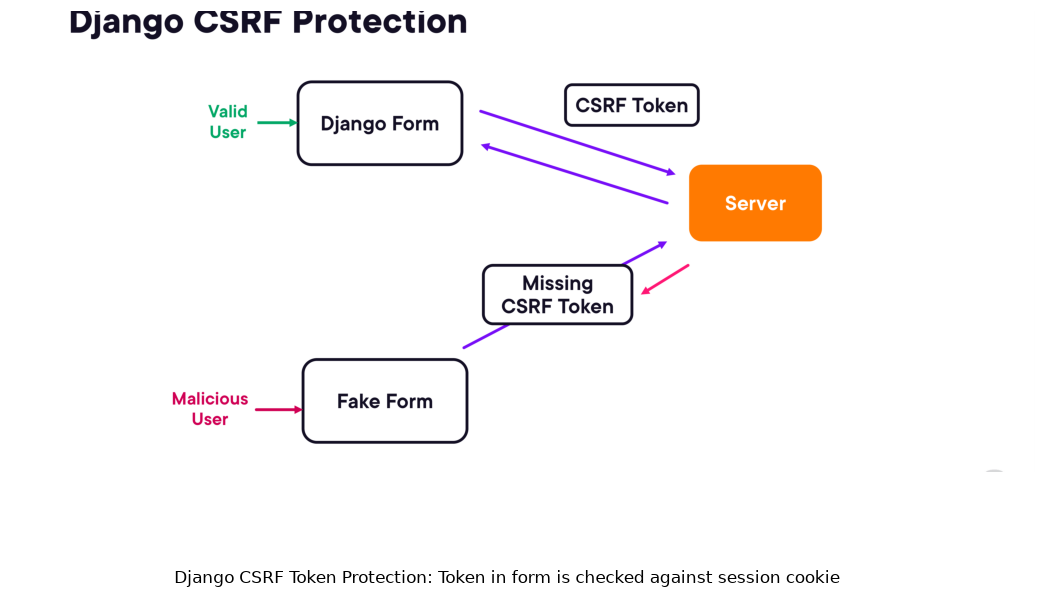

In [9]:
render_diagram(
    "assets/diagrams/csrf_token_protection.png",
    size=(11, 6),
    caption="Django CSRF Token Protection: Token in form is checked against session cookie"
)


### 9.3 How to use CSRF protection

1. Ensure `django.middleware.csrf.CsrfViewMiddleware` is in `MIDDLEWARE` (it is by default).
2. Add `{% csrf_token %}` inside every `<form method="post">` tag:

```html
<form method="post" action="{% url 'contact' %}">
    {% csrf_token %}
    {{ form.as_p }}
    <button type="submit">Send</button>
</form>
```

This renders a hidden input:
```html
<input type="hidden" name="csrfmiddlewaretoken" value="<token_value>">
```

3. For AJAX requests, include the token in a header:

```javascript
// Read the token from the cookie
function getCookie(name) {
    const value = `; ${document.cookie}`;
    const parts = value.split(`; ${name}=`);
    if (parts.length === 2) return parts.pop().split(';').shift();
}

fetch('/api/endpoint/', {
    method: 'POST',
    headers: {
        'X-CSRFToken': getCookie('csrftoken'),
        'Content-Type': 'application/json',
    },
    body: JSON.stringify({key: 'value'}),
});
```

### 9.4 Exempting a view from CSRF (use with care)

```python
from django.views.decorators.csrf import csrf_exempt

@csrf_exempt
def my_api_view(request):
    # Only do this if you have an alternative authentication mechanism
    ...
```

> **Warning:** Exempting views from CSRF without an alternative protection mechanism (e.g., API key in header, OAuth token) is a security vulnerability.

### 9.5 Troubleshooting CSRF errors

| Symptom | Likely cause |
|---------|-------------|
| 403 on every POST | Missing `{% csrf_token %}` in template |
| 403 after session expiry | Token tied to session — re-login |
| 403 in AJAX | CSRF header not sent |
| Works in dev, fails in production | `CSRF_TRUSTED_ORIGINS` not set for HTTPS domain |


---
## 10. Custom Validation Methods

*Source coverage: managing-form-validation-errors-slides.pdf, pages 3–4, 7–9*

Beyond using validators in a list, Django provides hooks for writing custom validation logic directly on the form class.

### 10.1 `clean_<fieldname>()` — per-field hook

Override this method to add field-specific validation or transformation after all validators have run:

```python
class CommentForm(forms.Form):
    name = forms.CharField(required=True, max_length=100)
    email = forms.EmailField(required=True)
    message = forms.CharField(widget=forms.Textarea)

    def clean_name(self):
        name = self.cleaned_data.get('name')
        if name and name.lower() in ('admin', 'root', 'system'):
            raise forms.ValidationError(
                "That username is reserved.",
                code='reserved_name',
            )
        return name.strip().title()   # Return the (possibly modified) clean value
```

**Rules:**
- The method must return the cleaned value (modified or unchanged).
- Raise `forms.ValidationError` to reject the value.
- At this point, `cleaned_data['name']` is already the Python-typed value from field validation.

### 10.2 `clean()` — cross-field validation hook

Override `clean()` when validation logic involves multiple fields:

```python
    def clean(self):
        cleaned_data = super().clean()                  # Always call super()
        name  = cleaned_data.get('name')
        email = cleaned_data.get('email')

        if name and email:
            domain = email.split('@')[-1]
            if name.lower() == 'example' and domain != 'example.com':
                raise forms.ValidationError(
                    "Users named 'example' must use an example.com email.",
                    code='name_email_mismatch',
                )

        return cleaned_data                             # Always return cleaned_data
```

**Rules:**
- Always call `super().clean()` first.
- Always return `cleaned_data`.
- Non-field errors go to `form.non_field_errors()` and `form.errors['__all__']`.
- Fields that failed earlier validation will be absent from `cleaned_data` — always use `.get()`.


In [10]:
# Conceptual demonstration of validation error collection
# (without a live Django instance)

class MockValidationError(Exception):
    def __init__(self, message, code=None):
        self.message = message
        self.code = code

def demo_clean_name(name_value):
    """Simulates clean_name() logic."""
    reserved = {'admin', 'root', 'system'}
    if name_value.lower() in reserved:
        raise MockValidationError(
            f"'{name_value}' is a reserved username.",
            code='reserved_name'
        )
    return name_value.strip().title()

test_names = ["alice", "Admin", "Root", "  bob  ", "System"]

print(f"{'Input':<15} {'Result / Error'}")
print("-" * 45)
for name in test_names:
    try:
        result = demo_clean_name(name)
        print(f"{name!r:<15} → {result!r}")
    except MockValidationError as e:
        print(f"{name!r:<15} ✗ ValidationError: {e.message}")


Input           Result / Error
---------------------------------------------
'alice'         → 'Alice'
'Admin'         ✗ ValidationError: 'Admin' is a reserved username.
'Root'          ✗ ValidationError: 'Root' is a reserved username.
'  bob  '       → 'Bob'
'System'        ✗ ValidationError: 'System' is a reserved username.


---
## 11. Form Lifecycle Method Overrides

*Source coverage: managing-form-validation-errors-slides.pdf, pages 5–9*

### 11.1 Full method signatures for `Form` overrides

```python
from django import forms

class AdvancedForm(forms.Form):

    def to_python(self, value):
        """Custom field override — convert raw input to Python type."""
        # Only override this in a custom Field subclass, not in Form directly.
        # Shown here for completeness.
        return super().to_python(value)

    def validate(self, value):
        """Custom field override — run required/empty check."""
        # Only override in a custom Field subclass.
        super().validate(value)

    def clean_name(self):
        """Called after field-level validation for the 'name' field."""
        name = self.cleaned_data.get('name')
        # ... custom logic ...
        return name

    def clean(self):
        """Called after all per-field clean methods."""
        cleaned_data = super().clean()
        # ... cross-field logic ...
        return cleaned_data
```

### 11.2 Full method signatures for `ModelForm` overrides

```python
from django.db import models
from typing import Collection

class AdvancedModel(models.Model):

    def clean(self):
        """Model-level cross-field validation — called by full_clean()."""
        return super().clean()

    def clean_fields(self, exclude: Collection[str] | None = None):
        """Validate each model field individually — rarely overridden."""
        return super().clean_fields(exclude)
```

### 11.3 Where to put each type of logic

| Logic type | Where to put it |
|------------|----------------|
| Convert/parse a single field value | `to_python()` on a custom Field subclass |
| Validate a single field independently | `validators=[]` list on the field |
| Validate + transform a single field | `clean_<fieldname>()` on the Form/ModelForm |
| Validate two or more fields together | `clean()` on the Form/ModelForm |
| Enforce uniqueness beyond `unique=True` | `validate_unique()` on the Model |
| Model-level business rules | `clean()` on the Model |

### 11.4 Raising validation errors

```python
from django.core.exceptions import ValidationError

# Simple string message
raise ValidationError("This field is required.")

# With error code (enables i18n and programmatic handling)
raise ValidationError("Invalid value.", code='invalid')

# With parameters for message interpolation
raise ValidationError(
    "Value %(value)s is not allowed.",
    code='invalid',
    params={'value': value},
)

# Multiple errors at once
raise ValidationError([
    ValidationError("Error one.", code='error_one'),
    ValidationError("Error two.", code='error_two'),
])

# Non-field error in clean()
self.add_error(None, "Cross-field validation failed.")

# Target a specific field in clean()
self.add_error('email', "This email is already registered.")
```


---
## 12. Customising Form Appearance

*Source coverage: managing-form-validation-errors-slides.pdf, pages 10–11; enhancing-user-experience-slides.pdf, pages 1–9*

Django's default form rendering is functional but unstyled. There are several approaches to add CSS styling.

### 12.1 Widget attributes — adding CSS classes in Python

Pass a `widget` argument with HTML attributes to any form field:

```python
from django import forms

class StyledCommentForm(forms.Form):
    name = forms.CharField(
        max_length=100,
        widget=forms.TextInput(attrs={
            'class': 'form-control',
            'placeholder': 'Your full name',
            'id': 'id_name',
        })
    )
    email = forms.EmailField(
        widget=forms.EmailInput(attrs={
            'class': 'form-control',
            'placeholder': 'your@email.com',
        })
    )
    message = forms.CharField(
        widget=forms.Textarea(attrs={
            'class': 'form-control',
            'rows': 5,
            'placeholder': 'Write your message here...',
        })
    )
```

This approach keeps styling decisions in Python — no template changes needed.

### 12.2 Adding CSS to the project

Static files (CSS, JS, images) go in the `static/` directory.

**Directory layout:**
```
application/
└── static/
    └── application/
        └── styles.css
```

**settings.py** (ensure these are set):
```python
STATIC_URL = '/static/'
STATICFILES_DIRS = [BASE_DIR / "static"]   # For project-level static files
```

**In templates**, load and use static files:
```html
{% load static %}
<!DOCTYPE html>
<html>
<head>
    <link rel="stylesheet" href="{% static 'application/styles.css' %}">
</head>
<body>
    ...
</body>
</html>
```

### 12.3 Example CSS for forms

```css
/* application/static/application/styles.css */

.form-control {
    display: block;
    width: 100%;
    padding: 0.375rem 0.75rem;
    font-size: 1rem;
    border: 1px solid #ced4da;
    border-radius: 0.25rem;
    transition: border-color 0.15s ease-in-out;
}

.form-control:focus {
    border-color: #86b7fe;
    outline: 0;
    box-shadow: 0 0 0 0.25rem rgba(13, 110, 253, 0.25);
}

.field-group {
    margin-bottom: 1rem;
}

.field-group label {
    display: block;
    margin-bottom: 0.5rem;
    font-weight: 600;
}

.error-list {
    color: #dc3545;
    font-size: 0.875rem;
    margin-top: 0.25rem;
}
```

### 12.4 Template with styling

```html
{% load static %}
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Comment Form</title>
    <link rel="stylesheet" href="{% static 'application/styles.css' %}">
</head>
<body>
    <div class="form-container">
        <h1>Leave a Comment</h1>
        <form method="post">
            {% csrf_token %}
            {% for field in form %}
                <div class="field-group">
                    {{ field.label_tag }}
                    {{ field }}
                    {% if field.errors %}
                        <ul class="error-list">
                            {% for error in field.errors %}
                                <li>{{ error }}</li>
                            {% endfor %}
                        </ul>
                    {% endif %}
                </div>
            {% endfor %}
            <button type="submit" class="btn-submit">Submit</button>
        </form>
    </div>
</body>
</html>
```


---
## 13. Handling and Displaying Validation Errors

*Source coverage: managing-form-validation-errors-slides.pdf, pages 3–11*

### 13.1 The `form.errors` dictionary

After calling `form.is_valid()` (which returns `False` when there are errors), you can inspect errors:

```python
# In a view after form.is_valid() returns False:
print(form.errors)
# {'name': ['This field is required.'], 'email': ['Enter a valid email address.']}

# As JSON (useful for AJAX responses):
import json
print(json.dumps(form.errors.as_json()))

# Access errors for a specific field:
print(form.errors['name'])
# ['This field is required.']

# Non-field errors (from clean()):
print(form.non_field_errors())
```

### 13.2 Displaying errors in templates

**Automatic (with as_p / as_ul / as_table):** Errors are included automatically.

**Manual rendering:**
```html
{% if form.non_field_errors %}
    <div class="alert alert-danger">
        {% for error in form.non_field_errors %}
            <p>{{ error }}</p>
        {% endfor %}
    </div>
{% endif %}

{% for field in form %}
    <div class="field-group {% if field.errors %}has-error{% endif %}">
        {{ field.label_tag }}
        {{ field }}
        {% if field.errors %}
            <ul class="error-list">
                {% for error in field.errors %}
                    <li>{{ error }}</li>
                {% endfor %}
            </ul>
        {% endif %}
        {% if field.help_text %}
            <small class="help-text">{{ field.help_text }}</small>
        {% endif %}
    </div>
{% endfor %}
```

### 13.3 Customising error messages

Override the default messages at the field level:

```python
class CommentForm(forms.Form):
    name = forms.CharField(
        required=True,
        error_messages={
            'required': 'Please enter your name.',
            'max_length': 'Your name cannot exceed %(limit_value)d characters.',
        }
    )
    email = forms.EmailField(
        error_messages={
            'required': 'We need your email address to reply.',
            'invalid':  'Please enter a valid email address.',
        }
    )
```

### 13.4 Using `add_error()` in `clean()`

`self.add_error(field, error)` is the preferred way to add errors during `clean()`:

```python
def clean(self):
    cleaned_data = super().clean()
    start = cleaned_data.get('start_date')
    end   = cleaned_data.get('end_date')

    if start and end and start >= end:
        self.add_error('end_date', 'End date must be after start date.')
        # Alternatively, add as a non-field error:
        # self.add_error(None, 'End date must be after start date.')

    return cleaned_data
```


---
## 14. Enhancing User Experience with CSS and Widgets

*Source coverage: enhancing-user-experience-slides.pdf, pages 1–11*

### 14.1 Comprehensive widget reference

Django provides a widget for every standard HTML input type:

| Widget | HTML rendered | Use for |
|--------|--------------|---------|
| `TextInput` | `<input type="text">` | Short text |
| `EmailInput` | `<input type="email">` | Email addresses |
| `NumberInput` | `<input type="number">` | Numbers |
| `URLInput` | `<input type="url">` | URLs |
| `PasswordInput` | `<input type="password">` | Passwords |
| `HiddenInput` | `<input type="hidden">` | Hidden data |
| `DateInput` | `<input type="date">` | Dates |
| `DateTimeInput` | `<input type="datetime-local">` | Date and time |
| `TimeInput` | `<input type="time">` | Time |
| `Textarea` | `<textarea>` | Multi-line text |
| `CheckboxInput` | `<input type="checkbox">` | Boolean |
| `Select` | `<select>` | Single choice |
| `SelectMultiple` | `<select multiple>` | Multiple choices |
| `RadioSelect` | `<input type="radio">` group | Single choice (visible) |
| `CheckboxSelectMultiple` | `<input type="checkbox">` group | Multiple choices (visible) |
| `FileInput` | `<input type="file">` | File upload |

### 14.2 Setting widget attributes on a ModelForm

In `Meta.widgets`, you can set the widget for any field:

```python
from django import forms
from .models import Comment

class CommentModelForm(forms.ModelForm):
    class Meta:
        model   = Comment
        fields  = ['name', 'email', 'message']
        widgets = {
            'name': forms.TextInput(attrs={
                'class':       'form-control',
                'placeholder': 'Full name',
                'autofocus':   True,
            }),
            'email': forms.EmailInput(attrs={
                'class':       'form-control',
                'placeholder': 'your@email.com',
            }),
            'message': forms.Textarea(attrs={
                'class': 'form-control',
                'rows':  6,
            }),
        }
```

### 14.3 Form `__init__` — dynamic styling

You can also apply CSS classes dynamically in `__init__`, useful when many fields share the same class:

```python
class CommentModelForm(forms.ModelForm):
    class Meta:
        model  = Comment
        fields = ['name', 'email', 'message']

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        for field_name, field in self.fields.items():
            field.widget.attrs['class'] = 'form-control'
            # Optionally add placeholders based on label:
            field.widget.attrs.setdefault(
                'placeholder',
                f"Enter {field.label.lower()}"
            )
```

### 14.4 Testing the complete form

After making styling changes, validate end-to-end:

1. Load the form at its URL (GET) — verify it renders without errors and looks correct.
2. Submit invalid data — verify validation errors appear in the right places with correct styling.
3. Submit valid data — verify the success redirect occurs and data is persisted (for ModelForm).
4. Check the admin (`/admin/`) to confirm saved records.

```bash
# Run the development server
python manage.py runserver

# Create a superuser to access admin
python manage.py createsuperuser
```


---
## 15. Reference Tables

### 15.1 Form vs ModelForm — when to choose what

| Factor | Use `Form` | Use `ModelForm` |
|--------|------------|-----------------|
| Backed by a model? | No | Yes |
| Need `save()` method? | No | Yes |
| Automatic field generation? | No | Yes |
| Custom field layout/types? | Easier | Requires Meta overrides |
| Validation integrated with model? | No | Yes |
| Use case | Search, contact, login | Create/edit model instances |

### 15.2 Full validation lifecycle comparison

| Step | `Form` | `ModelForm` |
|------|--------|------------|
| `to_python()` | ✓ | ✓ |
| `validate()` | ✓ | ✓ |
| `run_validators()` | ✓ | ✓ |
| `clean()` (field) | ✓ | ✓ |
| `clean_<field>()` | ✓ | ✓ |
| `clean()` (form) | ✓ | ✓ |
| `full_clean()` | — | ✓ |
| `clean_fields()` (model) | — | ✓ |
| `clean()` (model) | — | ✓ |
| `validate_unique()` | — | ✓ |
| `validate_constraints()` | — | ✓ (Django 3.2+) |

### 15.3 Django form field options quick reference

| Option | Type | Default | Description |
|--------|------|---------|-------------|
| `required` | bool | `True` | Field must have a value |
| `label` | str | Auto | Label text |
| `initial` | any | `None` | Default value (unbound form) |
| `help_text` | str | `''` | Hint text |
| `widget` | Widget | Field default | HTML widget |
| `validators` | list | `[]` | Extra validators |
| `error_messages` | dict | Field defaults | Custom error strings |
| `disabled` | bool | `False` | Render as disabled, ignore submitted value |

### 15.4 CSRF quick reference

| Item | Value |
|------|-------|
| Middleware | `django.middleware.csrf.CsrfViewMiddleware` |
| Template tag | `{% csrf_token %}` |
| Cookie name | `csrftoken` |
| Form field name | `csrfmiddlewaretoken` |
| AJAX header | `X-CSRFToken` |
| Exempt decorator | `@csrf_exempt` |
| Trusted origins setting | `CSRF_TRUSTED_ORIGINS` |
| Default response on failure | `403 Forbidden` |


---
## 16. Exercises and Knowledge Checks

*The exercises below are supplementary material created to reinforce the concepts from this course.*

### Exercise 1 — Build a Contact Form

Create a Django `Form` class for a contact page with the following fields:
- `first_name` (CharField, max 50 chars, required)
- `last_name` (CharField, max 50 chars, required)
- `email` (EmailField, required)
- `subject` (ChoiceField with options: "General", "Support", "Sales")
- `message` (CharField rendered as Textarea, min 20 chars)

**Additional requirements:**
- Validate that `first_name` and `last_name` contain only alphabetical characters (with spaces allowed).
- Add a `clean()` method that raises a non-field `ValidationError` if the `email` domain is `test.com`.

---

### Exercise 2 — Build a ModelForm

Given this model:

```python
class Product(models.Model):
    name        = models.CharField(max_length=200)
    description = models.TextField(blank=True)
    price       = models.DecimalField(max_digits=10, decimal_places=2)
    sku         = models.CharField(max_length=50, unique=True)
    created_at  = models.DateTimeField(auto_now_add=True)
```

1. Create a `ProductForm(ModelForm)` that includes `name`, `description`, `price`, and `sku`.
2. Add a `RegexValidator` to `sku` that requires it to match `^[A-Z]{2}-[0-9]{4}$` (e.g., `AB-1234`).
3. Add CSS class `form-control` to all widgets using `__init__`.
4. Write the corresponding view and template.

---

### Exercise 3 — Debug a CSRF Problem

A colleague shows you this template snippet:

```html
<form method="POST" action="/submit/">
    {{ form.as_p }}
    <button type="submit">Send</button>
</form>
```

What is wrong? How do you fix it?

**Answer:** `{% csrf_token %}` is missing. Add it immediately after the opening `<form>` tag:

```html
<form method="POST" action="/submit/">
    {% csrf_token %}
    {{ form.as_p }}
    <button type="submit">Send</button>
</form>
```

---

### Exercise 4 — Validation lifecycle tracing

For a `ModelForm` backed by a model that has `unique=True` on the `email` field:

List, in order, every validation method that Django calls when you call `form.is_valid()` on a bound form with valid data.

**Answer:**
1. `to_python()` — per field
2. `validate()` — per field
3. `run_validators()` — per field
4. `clean()` — per field
5. `clean_<fieldname>()` — per field (form-level)
6. `clean()` — form-level
7. `full_clean()` — model-level entry point (calls 8–10)
8. `clean_fields()` — model fields
9. `clean()` — model
10. `validate_unique()` — enforces unique constraints

---

### Exercise 5 — Regex challenge

Write a `RegexValidator` that:
- Allows only letters (upper and lower case) and single spaces between words.
- Does not allow leading or trailing spaces.
- Does not allow consecutive spaces.

*Hint: `^[A-Za-z]+( [A-Za-z]+)*$`*


---
## 17. Final Assessment

*Supplementary assessment covering all modules.*

**Question 1.** What is the difference between a bound and an unbound form?

> **Answer:** An *unbound* form has no data attached (created with no arguments) — it renders empty and `is_valid()` always returns `False`. A *bound* form is created with `data=request.POST` and can be validated.

---

**Question 2.** In which order does Django execute validation for a form field?

> **Answer:** `to_python()` → `validate()` → `run_validators()` → `clean()` (field level) → `clean_<fieldname>()` (form level) → `clean()` (form level).

---

**Question 3.** What does `form.save(commit=False)` do?

> **Answer:** It creates the model instance and populates it with form data but does **not** call `.save()` on the database. This lets you modify the instance (add extra fields not in the form) before persisting it.

---

**Question 4.** What HTTP status code does Django return when a CSRF token is missing or invalid?

> **Answer:** **403 Forbidden**.

---

**Question 5.** Where should you use `self.add_error()` vs raising `ValidationError`?

> **Answer:** Inside `clean()` or `clean_<field>()`, both work. However, `self.add_error(field_name, error)` is preferred in `clean()` because it targets a specific field or non-field errors cleanly. Raising `ValidationError` directly in `clean()` produces a non-field error by default.

---

**Question 6.** Name three built-in Django validators from `django.core.validators`.

> **Answer:** Any three of: `RegexValidator`, `EmailValidator`, `URLValidator`, `MaxValueValidator`, `MinValueValidator`, `MaxLengthValidator`, `MinLengthValidator`, `FileExtensionValidator`.

---

**Question 7.** What is the purpose of `validate_unique()` in the ModelForm lifecycle?

> **Answer:** It enforces `unique=True` and `unique_together` constraints defined on model fields. Without it, a form could accept values that would cause a database integrity error on `INSERT`.

---

**Question 8.** How do you add CSS classes to form widgets without modifying each field individually?

> **Answer:** Override `__init__` on the form and iterate over `self.fields`, adding the class to `field.widget.attrs['class']` for each field.

---

**Question 9.** Write the regex pattern that allows letters and spaces but not leading/trailing spaces or consecutive spaces.

> **Answer:** `^[A-Za-z]+( [A-Za-z]+)*$`

---

**Question 10.** What does `{% csrf_token %}` render in the HTML output?

> **Answer:** A hidden input field:
> ```html
> <input type="hidden" name="csrfmiddlewaretoken" value="<token>">
> ```
> where `<token>` is a session-tied secret used by `CsrfViewMiddleware` to verify the request origin.
